# Integrar LLM en LangGraph

Hoy vamos a  conectar LangGraph con un modelo de inteligencia artificial real para que analice los datos de un servidor Linux y genere un diagnóstico.

Al terminar esta clase tendrás un programa Python que:
1. Recibe el nombre de un servidor Linux.
2. Obtiene valores simulados de CPU, memoria y procesos.
3. Decide si existe alguna anomalía.
4. Envía los datos a un LLM.
5. Recibe un diagnóstico en lenguaje natural.

La novedad: diagnosticar_llm() será una función Python que llama a un modelo de IA. Para LangGraph sigue siendo un nodo como cualquier otro.


## Diferencia entre LangGraph, LangChain y LLM
**Componente**
- LangGraph:	Orquesta nodos, estados y decisiones.
- LangChain:	Ofrece integraciones y abstracciones para trabajar con LLM y herramientas.
- LLM:	Interpreta los datos y genera el diagnóstico.

Para esta clase usaremos ChatOpenAI, proporcionado por la integración langchain-openai. LangGraph no necesita conocer los detalles de la API del modelo.

Es importante comprender que LangChain y LangGraph no sustituyen al LLM. Son componentes del software que estamos desarrollando.

````
LangGraph
   │
   └── Nodo diagnosticar_llm()
                │
                ▼
           ChatOpenAI
                │
                ▼
           Modelo GPT
                │
                ▼
           Diagnóstico
````

Desde la carpeta mi-primer-agente añadir: 
````bash
uv add langgraph langchain-openai
````

Necesitarás una API key de OpenAI, que puedes crear en [OpenAI Platform](https://platform.openai.com/api-keys).
La API de OpenAI tiene facturación independiente de una suscripción a ChatGPT.
En Linux o macOS configura la clave:
````bash
export OPENAI_API_KEY="tu-api-key"
````
**No incluyas la clave directamente en el código Python ni la subas a Git.**

Para esta práctica utilizaremos gpt-4.1-mini, un modelo compatible con ChatOpenAI. El modelo se puede cambiar posteriormente.

# Resumen de la clase 3

| Concepto | Qué has aprendido |
|---|---|
| `ChatOpenAI` | Permite conectar Python con un modelo GPT. |
| `system` | Define instrucciones y límites de comportamiento. |
| `human` | Proporciona los datos a analizar. |
| `llm.invoke()` | Realiza la llamada al modelo. |
| `respuesta.content` | Contiene el contenido de la respuesta. |
| Nodo LLM | Una función Python que utiliza un modelo de IA. |

## Documentación oficial

- [Integración ChatOpenAI](https://docs.langchain.com/oss/python/integrations/chat/openai)
- [LangGraph Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api)


# Ejecucion del codigo

- Prueba A: servidor con CPU elevada
Ejecutar el codigo:

````bash
uv run python main.py srv-oracle-01
````
- Prueba B: servidor sin anomalías

````bash
uv run python main.py srv-linux-ok
````

[GRAPH] Grafo guardado en: /root/9.AI/mi-primer-agente/notebooks/graph.png


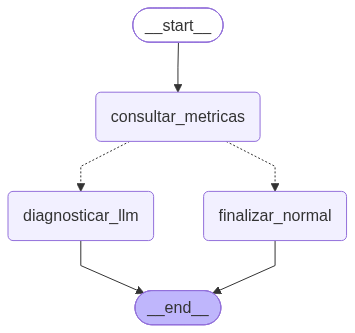

Aviso: OPENAI_API_KEY no configurada.
Será necesaria si se detecta una anomalía.
[NODE] Consultando --f=/run/user/0/jupyter/runtime/kernel-v36c605a2b2106911d3fd5a255adfab54bf4c58390.json
[ROUTER] Anomalía detectada
[NODE] Solicitando diagnóstico al LLM


OpenAIError: Missing credentials. Please pass an `api_key`, `workload_identity`, `admin_api_key`, or set the `OPENAI_API_KEY` or `OPENAI_ADMIN_KEY` environment variable.

In [3]:
import os
import sys
from pathlib import Path
from typing import TypedDict, Literal

from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from IPython import get_ipython
from IPython.display import Image, display


# ==================================================
# 1. STATE: Información compartida
# ==================================================

class AgentState(TypedDict):
    servidor: str
    cpu: int
    memoria: int
    proceso: str
    diagnostico: str


# ==================================================
# 2. NODE: Consultar métricas
# ==================================================

def consultar_metricas(state: AgentState):
    print(f"[NODE] Consultando {state['servidor']}")

    # Simulamos métricas de Linux.
    # En la clase 4 crearemos herramientas reales.
    if state["servidor"] == "srv-linux-ok":
        return {
            "cpu": 25,
            "memoria": 40,
            "proceso": "systemd"
        }

    return {
        "cpu": 95,
        "memoria": 88,
        "proceso": "oracle"
    }


# ==================================================
# 3. ROUTER: Decidir si hace falta diagnóstico
# ==================================================

def decidir_ruta(
    state: AgentState
) -> Literal["diagnosticar_llm", "finalizar_normal"]:

    if state["cpu"] > 90 or state["memoria"] > 90:
        print("[ROUTER] Anomalía detectada")
        return "diagnosticar_llm"

    print("[ROUTER] Métricas normales")
    return "finalizar_normal"


# ==================================================
# 4. NODE: Diagnóstico mediante un LLM
# ==================================================

def diagnosticar_llm(state: AgentState):
    print("[NODE] Solicitando diagnóstico al LLM")

    # Crear el cliente del modelo
    llm = ChatOpenAI(
        model="gpt-4.1-mini",
        temperature=0
    )

    # Instrucciones para el modelo
    mensajes = [
        (
            "system",
            "Eres un asistente experto en diagnóstico Linux. "
            "Analiza las métricas proporcionadas. "
            "Explica las posibles causas y recomienda "
            "comprobaciones adicionales. "
            "No inventes evidencias ni afirmes haber "
            "ejecutado comandos. "
            "No propongas cambios destructivos."
        ),
        (
            "human",
            f"""
            Servidor: {state['servidor']}
            CPU: {state['cpu']}%
            Memoria: {state['memoria']}%
            Proceso observado: {state['proceso']}

            Genera un diagnóstico técnico breve
            en español.
            """
        )
    ]

    # Llamada real al LLM
    respuesta = llm.invoke(mensajes)

    # Actualizar el estado
    return {
        "diagnostico": str(respuesta.content)
    }


# ==================================================
# 5. NODE: Finalizar sin llamar al LLM
# ==================================================

def finalizar_normal(state: AgentState):
    print("[NODE] No se necesita diagnóstico con IA")

    return {
        "diagnostico": "Métricas dentro de los umbrales."
    }


# ==================================================
# 6. CONSTRUIR LANGGRAPH
# ==================================================

builder = StateGraph(AgentState)

builder.add_node("consultar_metricas", consultar_metricas)
builder.add_node("diagnosticar_llm", diagnosticar_llm)
builder.add_node("finalizar_normal", finalizar_normal)

builder.add_edge(START, "consultar_metricas")

builder.add_conditional_edges(
    "consultar_metricas",
    decidir_ruta,
    {
        "diagnosticar_llm": "diagnosticar_llm",
        "finalizar_normal": "finalizar_normal"
    }
)

builder.add_edge("diagnosticar_llm", END)
builder.add_edge("finalizar_normal", END)

graph = builder.compile()


# ==================================================
# 7. VISUALIZAR EL GRAFO
# ==================================================

# Generar la imagen PNG del grafo
png_data = graph.get_graph().draw_mermaid_png()

# Guardar el PNG en el mismo directorio que main.py
ruta_png = Path("graph.png")
ruta_png.write_bytes(png_data)

print(f"[GRAPH] Grafo guardado en: {ruta_png.resolve()}")

# Si estamos en Jupyter, mostrar la imagen directamente
ipython = get_ipython()

if ipython is not None and "IPKernelApp" in ipython.config:
    display(Image(data=png_data))


# ==================================================
# 8. EJECUTAR
# ==================================================

if __name__ == "__main__":

    if len(sys.argv) != 2:
        print("Uso: uv run python main.py <servidor>")
        sys.exit(1)

    servidor = sys.argv[1]

    if not os.getenv("OPENAI_API_KEY"):
        print("Aviso: OPENAI_API_KEY no configurada.")
        print("Será necesaria si se detecta una anomalía.")

    resultado = graph.invoke({
        "servidor": servidor,
        "cpu": 0,
        "memoria": 0,
        "proceso": "",
        "diagnostico": ""
    })

    print("\n========== DIAGNÓSTICO ==========")
    print(resultado["diagnostico"])